# Tasks reported in AI-use disclosures (RQ2: tasks)

**Owner:** Aidin. Logic in `aidin_tasks.py`.

**Input:** `disclosures_master.xlsx`, the verified disclosures from the shared gate (Hemanth, `rj_disclosure_location.py`), keyed by `disclosure_id`. This notebook does not decide what counts as a disclosure; it only codes **what the AI was used for**.

**Unit:** the disclosure paragraph (15 paragraphs, 14 papers). Multi-label: a paragraph can report several tasks.

**Codebook:** two levels. Stage: *paper production* (deductive codes from RQ2: language editing, translating the paper, coding, literature, data analysis, figures) or *research instrument* (inductive codes added after a first reading: data / prompt generation, annotation / judging, summarising / paraphrasing, translating study materials, decision support), plus explicit non-use and unspecified. Rule: code the action of the AI itself, not what its output was later used for.

**Steps:** A. coding workbook with keyword hints → *every paragraph read and corrected by hand in Excel* → B. results → C. figure → D. export

In [1]:
# Run once if needed:
# %pip install pandas openpyxl matplotlib
import importlib, os
import pandas as pd
import aidin_tasks as at
importlib.reload(at)
pd.set_option("display.max_colwidth", 120)
MASTER = "disclosures_master.xlsx"
WORKBOOK = "aidin_tasks_coding.xlsx"

## A. Coding workbook
Keyword hints are pre-filled from the sentences that mention an AI tool (`ai_sentences`). The coder reads every paragraph and corrects the orange task columns; `auto_labels` keeps the untouched hints.

⚠️ The cell only creates the workbook if it does not exist yet, so the manual codes are never overwritten.

In [2]:
master = at.load_master(MASTER)
if not os.path.exists(WORKBOOK):
    at.export_coding_workbook(master, WORKBOOK)
else:
    print(f"{WORKBOOK} already exists (manual codes kept). Delete it to start again.")

aidin_tasks_coding.xlsx already exists (manual codes kept). Delete it to start again.


## B. Results
* `tasks`: paragraphs and papers per task, with the share of the disclosing papers.
* `stages`: research instrument vs paper production.
* `by_year`: papers per task per year.
* `auto_vs_final`: how often the keyword hints agreed with the final manual codes (and what was changed).

In [3]:
res = at.summarise(WORKBOOK)
print(f"{res['n_paragraphs']} disclosure paragraphs from {res['n_papers']} papers")
display(res["tasks"])
display(res["stages"])
display(res["by_year"])
display(res["auto_vs_final"])
res["per_paper"]

15 disclosure paragraphs from 14 papers


,stage,task,paragraphs,papers,share_of_disclosing_papers_%
3,research_instrument,data_generation,7,6,42.9
5,research_instrument,summarising_paraphrasing,3,3,21.4
2,research_instrument,annotation_judging,2,2,14.3
0,other,explicit_non_use,1,1,7.1
1,paper_production,coding,1,1,7.1
4,research_instrument,decision_support,1,1,7.1
6,research_instrument,translation_materials,1,1,7.1


,stage,paragraphs,papers
0,other,1,1
1,paper_production,1,1
2,research_instrument,14,13


year,2023,2024,2025
task,,,
annotation_judging,0,1,1
coding,0,0,1
data_generation,0,5,1
decision_support,0,1,0
explicit_non_use,0,0,1
summarising_paraphrasing,1,0,2
translation_materials,0,0,1


,decisions,same,agreement_%,paragraphs_changed,changes
0,195,193,99.0,2,2025-000060-p070:data_generation 1->0; 2025-000087-p111:figures 1->0


,year,paper_id,tasks,stages
0,2023,000047,summarising_paraphrasing,research_instrument
1,2024,000014,data_generation,research_instrument
2,2024,000027,data_generation,research_instrument
3,2024,000032,data_generation,research_instrument
4,2024,000075,data_generation,research_instrument
5,2024,000090,annotation_judging,research_instrument
6,2024,000099,data_generation,research_instrument
7,2024,000112,decision_support,research_instrument
8,2025,000001,translation_materials,research_instrument
9,2025,000029,annotation_judging,research_instrument


## C. Figure
Zero rows are kept on purpose: they show which planned (deductive) codes never occurred.

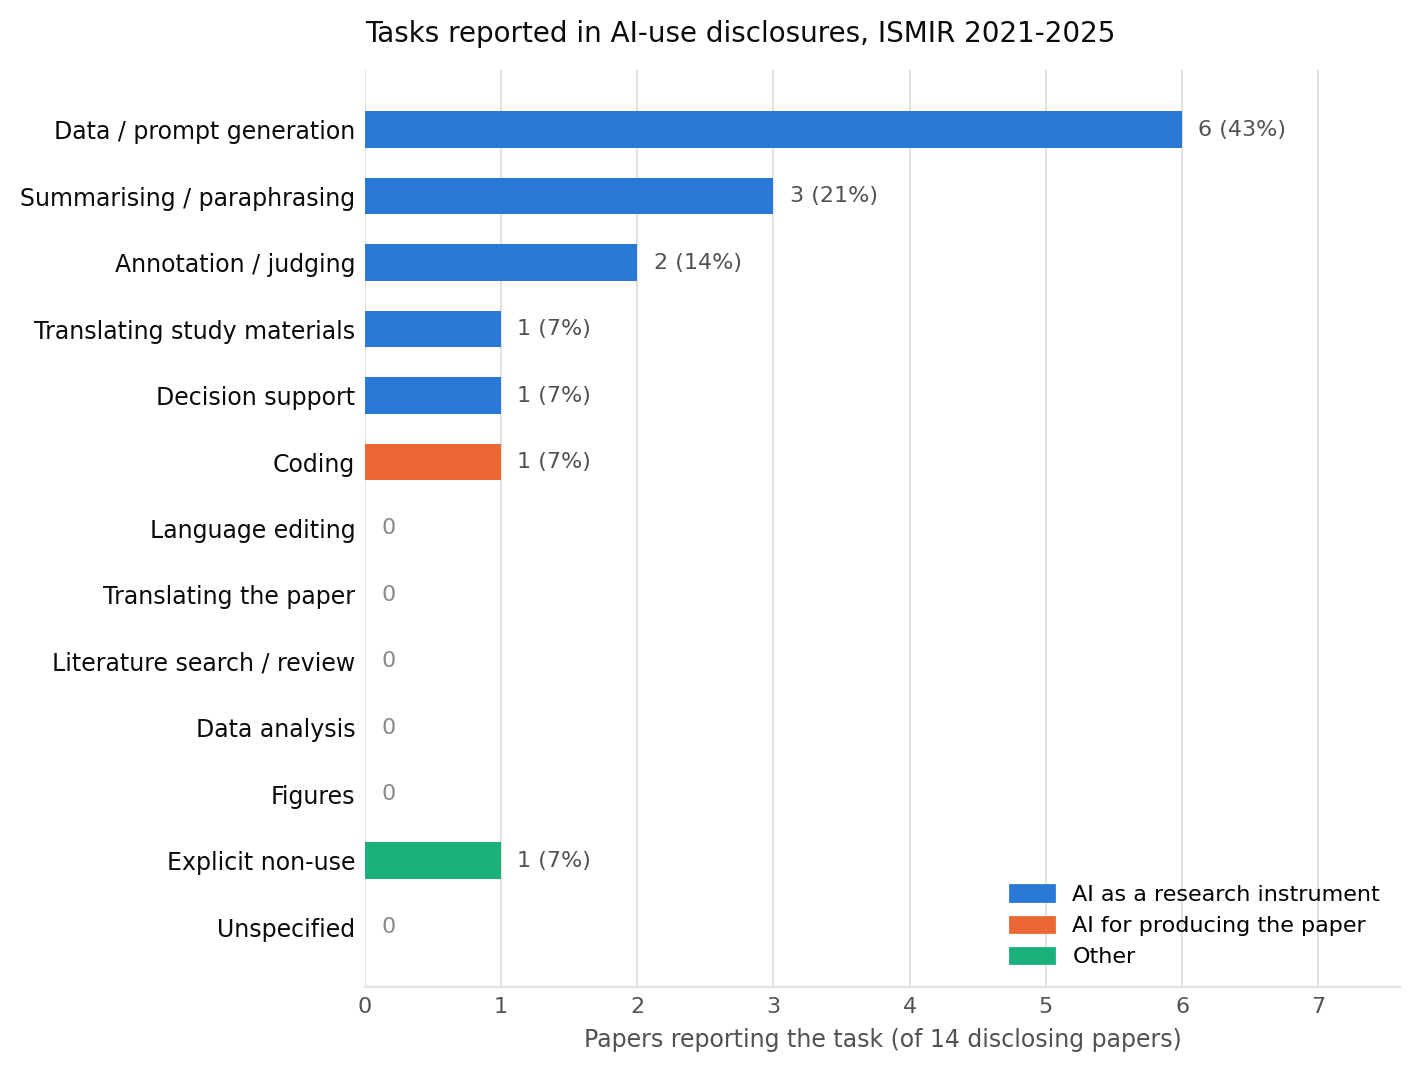

In [4]:
at.plot_tasks(WORKBOOK, "aidin_tasks_figure.png");

## D. Export
Tables for the paper and for teammates (keyed by year / paper_id).

In [5]:
res["tasks"].to_csv("aidin_tasks_summary.csv", index=False)
res["by_year"].to_csv("aidin_tasks_by_year.csv")
res["per_paper"].to_csv("aidin_tasks_per_paper.csv", index=False)
print("Saved aidin_tasks_summary.csv, aidin_tasks_by_year.csv, aidin_tasks_per_paper.csv")

Saved aidin_tasks_summary.csv, aidin_tasks_by_year.csv, aidin_tasks_per_paper.csv
